11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 164s 2s/step - accuracy: 0.4677 - loss: 2.6489
Epoch 2/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 195s 2s/step - accuracy: 0.7943 - loss: 0.6799

Training: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 70s 662ms/step - accuracy: 0.6810 - loss: 1.1211
Epoch 2/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 60s 642ms/step - accuracy: 0.8827 - loss: 0.5060

Training: GoogLeNet-family (InceptionV3)
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 33s 265ms/step - accuracy: 0.6703 - loss: 1.0876
Epoch 2/2
94/94 ━━━━━━━━━━━━━━━━━━━━ 25s 267ms/step - accuracy: 0.8340 - loss: 0.5682

FINAL COMPARISON
                  Architecture  Accuracy (%)  Test Loss  Time (seconds)
                         VGG16          83.4     0.5501          490.00
                      ResNet50          86.

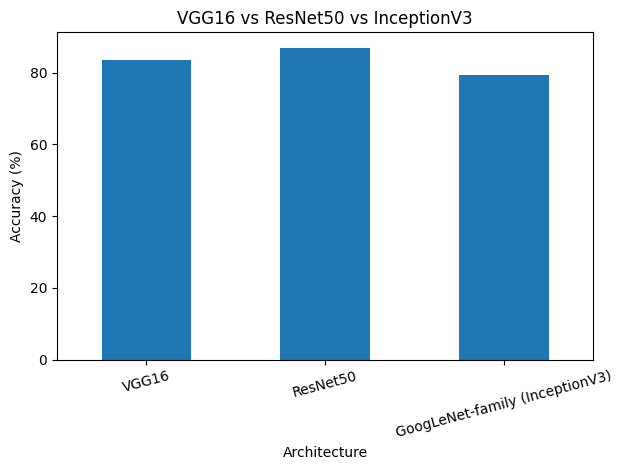

In [1]:

import tensorflow as tf
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre
from tensorflow.keras.applications.inception_v3 import preprocess_input as inc_pre

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train, y_train = x_train[:3000], y_train[:3000]
x_test, y_test = x_test[:1000], y_test[:1000]

def prepare(x, preprocess):
    x = np.repeat(x[..., None], 3, axis=-1)
    x = tf.image.resize(x, (75, 75)).numpy()
    return preprocess(x.astype("float32"))

architectures = {
                "VGG16": (VGG16, vgg_pre),
                    "ResNet50": (ResNet50, res_pre),
                        "GoogLeNet-family (InceptionV3)": (InceptionV3, inc_pre)
                        }
results = []
for name, (architecture, preprocess) in architectures.items():
  print("\nTraining:", name)
  X_train = prepare(x_train, preprocess)
  X_test = prepare(x_test, preprocess)
  base = architecture(
                                                weights="imagenet", include_top=False,
                                                        input_shape=(75, 75, 3))
  base.trainable = False
  model = models.Sequential([layers.Input(shape=(75, 75, 3)),
                                                                                    base,
                                                                                            layers.GlobalAveragePooling2D(),
                                                                                                    layers.Dense(10, activation="softmax")
                                                                                                        ])

  model.compile(optimizer="adam",loss="sparse_categorical_crossentropy", metrics=["accuracy"])


  start = time.time()
  model.fit(X_train, y_train, epochs=2, batch_size=32)
  loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
  results.append([
                        name, round(accuracy * 100, 2),
                                round(loss, 4), round(time.time() - start, 2)
                                    ])

  del model, base, X_train, X_test
  tf.keras.backend.clear_session()
df = pd.DataFrame(results, columns=[
      "Architecture", "Accuracy (%)", "Test Loss", "Time (seconds)"
      ])

print("\nFINAL COMPARISON")
print(df.to_string(index=False))
df.plot(x="Architecture", y="Accuracy (%)", kind="bar",
legend=False, ylabel="Accuracy (%)",
title="VGG16 vs ResNet50 vs InceptionV3")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
data = pd.read_csv(url)
values = data["Passengers"].values.astype("float32")

mean, std = values.mean(), values.std()
values = (values - mean) / std

X, y = [], []
for i in range(len(values) - 12):
    X.append(values[i:i+12])
    y.append(values[i+12])

X, y = np.array(X), np.array(y)
X = X.reshape(-1, 12, 1)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
rnn = models.Sequential([
            layers.Input(shape=(12, 1)),
                layers.Bidirectional(layers.SimpleRNN(16)),
                    layers.Dense(1)
                    ])

rnn.compile(optimizer="adam", loss="mse")
rnn.fit(X_train, y_train, epochs=30, verbose=0)

ffn = models.Sequential([
                        layers.Input(shape=(12,)),
                            layers.Dense(32, activation="relu"),
                                layers.Dense(16, activation="relu"),
                                    layers.Dense(1)
                                    ])

ffn.compile(optimizer="adam", loss="mse")
ffn.fit(X_train.reshape(-1, 12), y_train, epochs=30, verbose=0)
rnn_pred = rnn.predict(X_test, verbose=0).flatten()
ffn_pred = ffn.predict(X_test.reshape(-1, 12), verbose=0).flatten()
print("Bidirectional RNN MSE:", round(np.mean((y_test-rnn_pred)**2), 4))
print("Feed-Forward NN MSE:", round(np.mean((y_test-ffn_pred)**2), 4))
plt.plot(y_test * std + mean, label="Actual")
plt.plot(rnn_pred * std + mean, label="Bidirectional RNN")
plt.plot(ffn_pred * std + mean, label="Feed-Forward NN")
plt.xlabel("Test Month")
plt.ylabel("Passengers")
plt.title("Airline Passenger Prediction")
plt.legend()
plt.show()
